In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import keras
import tensorflow as tf
from sklearn.model_selection import train_test_split

# 1. Load dataset (grayscale, resize)

In [2]:
UKURAN = 250
data_path = "Rice"
kelas = sorted(os.listdir(data_path))
print(kelas)

x, y = [], []
for label, nama_kelas in enumerate(kelas):
    folder = os.path.join(data_path, nama_kelas)
    print(folder)

    for nama_file in os.listdir(folder):
        if nama_file.endswith("Thumbs.db"):
            continue

        gambar = keras.utils.load_img(os.path.join(folder, nama_file), color_mode="grayscale", target_size=(UKURAN, UKURAN))
        x.append(np.array(gambar))
        y.append(label)

x = np.array(x)
y = np.array (y)

['Arborio', 'Basmati', 'Ipsala', 'Jasmine', 'Karacadag']
Rice\Arborio
Rice\Basmati
Rice\Ipsala
Rice\Jasmine
Rice\Karacadag


In [3]:
print("Jumlah gambar: ", len(x))
print("Ukuran x: ", x.shape)
print("Ukuran y: ", y.shape)

Jumlah gambar:  500
Ukuran x:  (500, 250, 250)
Ukuran y:  (500,)


# 2. Preprocessing (normalisasi + one hot encoding)

In [4]:
x = x.astype("float32") / 255.0
y = keras.utils.to_categorical(y, num_classes=len(kelas))

print(x.shape)
print(y.shape)
print(y[0])

(500, 250, 250)
(500, 5)
[1. 0. 0. 0. 0.]


# 3. Split dataset 80 10 10

In [5]:
# 80 train, 20 temp
x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.2, random_state=42)

# 20 temp -> 10 val, 10 test
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, random_state=42)

print("Training:", len(x_train))
print("Validation:", len(x_val))
print("Testing:", len(x_test))

Training: 400
Validation: 50
Testing: 50


# 4. DCNN

In [8]:
model = keras.Sequential([
    # input layer
    keras.layers.Input(shape=(UKURAN, UKURAN, 1)),

    # hidden layer
    keras.layers.Conv2D(32, (3,3), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2,2), strides=2),

    keras.layers.Conv2D(64, (3,3), activation="relu"),
    keras.layers.Conv2D(64, (3,3), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2,2), strides=2),

    keras.layers.Flatten(),

    # output layer
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(len(kelas), activation="softmax"),
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 248, 248, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 124, 124, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 122, 122, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 120, 120, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 60, 60, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 230400)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │    29,491,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,555,653 (112.75 MB)

 Trainable params: 29,555,653 (112.75 MB)

 Non-trainable params: 0 (0.00 B)

# 5. Training

In [10]:
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
history = model.fit(x_train, y_train, batch_size=32, epochs=10, validation_data=(x_val, y_val))

Epoch 1/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.7175 - loss: 0.7159 - val_accuracy: 0.8600 - val_loss: 0.3993
Epoch 2/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.8900 - loss: 0.3284 - val_accuracy: 0.9000 - val_loss: 0.3774
Epoch 3/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.9200 - loss: 0.2023 - val_accuracy: 0.9200 - val_loss: 0.2518
Epoch 4/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.9500 - loss: 0.1458 - val_accuracy: 0.9200 - val_loss: 0.3396
Epoch 5/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.9425 - loss: 0.1446 - val_accuracy: 0.9400 - val_loss: 0.2188
Epoch 6/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.9600 - loss: 0.1336 - val_accuracy: 0.9400 - val_loss: 0.2000
Epoch 7/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.9825 - loss: 0.0637 - val_accuracy: 0.8800 - val_loss: 0.4602
Epoch 8/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.9825 - loss: 0.0625 - val_accuracy: 0.9600 - val_loss:

# 6. Show Prediksi (9 gambar data test)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step


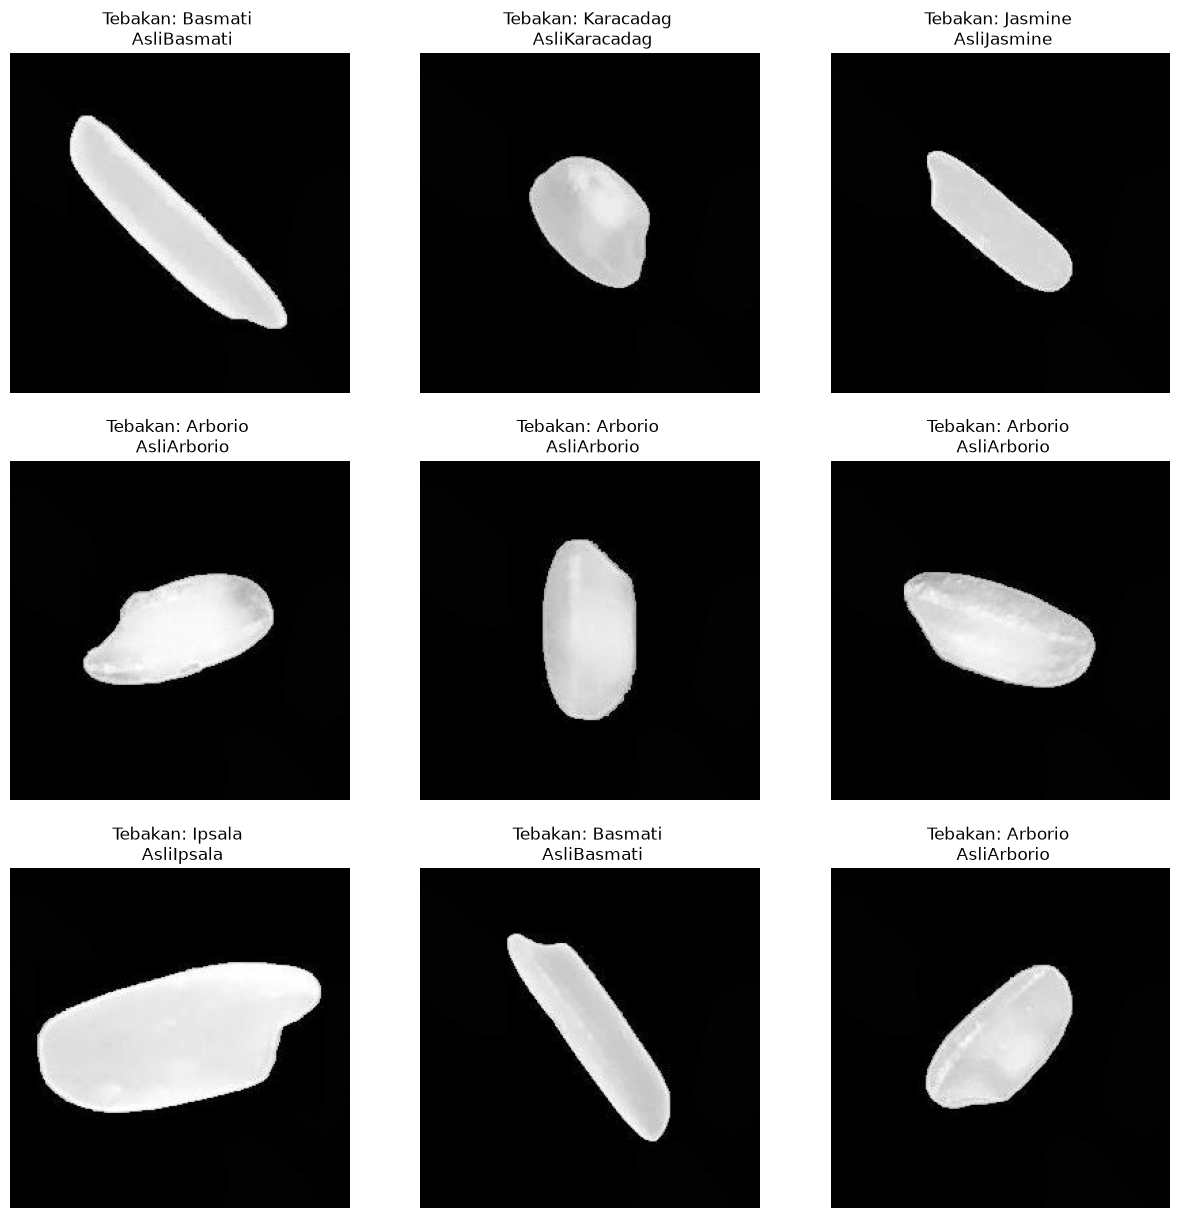

In [20]:
prediksi = model.predict(x_test)
tebakan = np.argmax(prediksi, axis=1)
real = np.argmax(y_test, axis=1)

plt.figure(figsize=(15,15))
for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(f"Tebakan: {kelas[tebakan[i]]} \n Asli{kelas[real[i]]}")
    plt.axis("off")

plt.show()

# 7. Evaluate

In [22]:
loss, accuracy = model.evaluate(x_test, y_test)
print("Loss di data test:", loss)
print("Accuracy di data test:", accuracy)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - accuracy: 0.9600 - loss: 0.1855
Loss di data test: 0.18549737334251404
Accuracy di data test: 0.9599999785423279


# 8. Plotting Accuracy & Loss

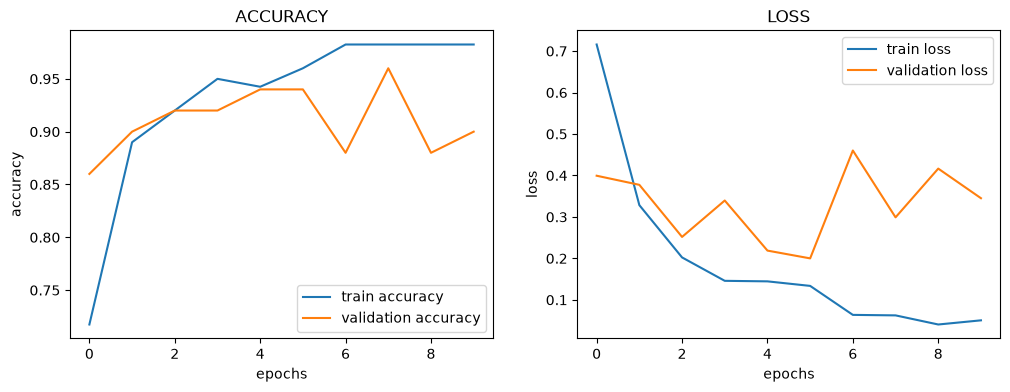

In [26]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="validation accuracy")
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.title("ACCURACY")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.xlabel("epochs")
plt.ylabel("loss")
plt.title("LOSS")
plt.legend()

plt.show()